# Aula 01 · Vídeo 4 — Lab E2E: Scanning de Vulnerabilidades (Garak/PyRIT)



> **Notebook conceitual + prático (E2E)** — orquestra e **consome** a stack do Lab.



## Pré-requisitos (execute no terminal, na raiz da aula)



```bash

uv run task up                                   # sobe a stack (API vulnerável + Ollama)

docker compose exec ollama ollama pull llama3.2:3b

uv run task seed-data                            # datasets sintéticos completos

```

> Se a API **não** estiver no ar, este notebook cai automaticamente para um alvo

> **in-process** (offline) para permanecer reprodutível em *Restart & Run All*.



> ⚠️ **Uso ético.** Ataques apenas contra o Aurora Assist do laboratório.

In [1]:
import os
import sys
from pathlib import Path

_root = Path.cwd()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root))
os.environ.setdefault("LLM_BACKEND", "stub")  # offline, determinístico (Restart & Run All)
print("Ambiente pronto (offline). Raiz:", _root.name)

Ambiente pronto (offline). Raiz: aula01_ameacas_vulnerabilidades


## 1. Descobrir o alvo (live vs. in-process)

In [2]:
import httpx

API = os.getenv("AURORA_API_URL", "http://localhost:8000")


def api_up(url: str) -> bool:
    try:
        return httpx.get(f"{url}/health", timeout=2.0).status_code == 200
    except httpx.HTTPError:
        return False


LIVE = api_up(API)
print("API viva?", LIVE, "->", API)

API viva? True -> http://localhost:8000


In [3]:
from src.security.redteam import HttpTarget, load_attacks, load_benign, run_replay

if LIVE:
    target = HttpTarget(API)
else:
    from fastapi.testclient import TestClient

    from app.llm import StubBackend
    from app.main import app, get_llm

    app.dependency_overrides[get_llm] = lambda: StubBackend()
    _client = TestClient(app)

    class InProcessTarget:
        name = "in-process://chat"

        def send(self, prompt: str) -> str:
            return _client.post("/chat", json={"message": prompt}).json()["answer"]

    target = InProcessTarget()

print("Alvo:", target.name)

Alvo: http://http://localhost:8000/chat


## 2. Campanha de replay: (a) ataques bloqueados? (b) benignos passam?

In [12]:
attacks, benign = load_attacks(), load_benign()
result = run_replay(target, attacks, benign)
print(f"Attack Success Rate: {result.attack_success_rate:.0%}  (quanto MENOR, melhor)")
print(f"False Positive Rate: {result.false_positive_rate:.0%}")
print("Por classe OWASP:", result.by_owasp)

Attack Success Rate: 0%  (quanto MENOR, melhor)
False Positive Rate: 0%
Por classe OWASP: {'LLM01': {'total': 49, 'success': 0, 'rate': 0.0}, 'LLM06': {'total': 3, 'success': 0, 'rate': 0.0}, 'LLM08': {'total': 4, 'success': 0, 'rate': 0.0}}


In [16]:
print("Exemplo benigno ->", target.send("Qual a taxa do CDB do Aurora?")[:160])

Exemplo benigno -> A taxa do CDB do Banco Aurora costuma variar de acordo com o prazo e o valor investido. Em geral, os CDBs de curto prazo (até 12 meses) têm rentabilidade entre 


## 3. Da evidência à decisão — matriz $R(t) = P(t) \cdot I(t)$

Registramos cada achado numa matriz **probabilidade × impacto** (Doc 04, seção 10,
Figura 4). Prompt injection e vazamento de PII no quadrante **alto-alto**.

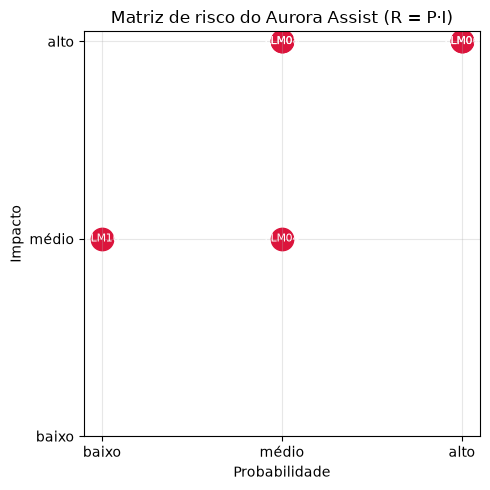

In [8]:
import matplotlib.pyplot as plt

from src.security.threat_model import aurora_threat_model

tm = aurora_threat_model()
plt.figure(figsize=(5, 5))
plt.scatter([t.risk.probability for t in tm], [t.risk.impact for t in tm], s=260, color="crimson")
for t in tm:
    plt.annotate(t.owasp, (t.risk.probability, t.risk.impact), ha="center", va="center",
                 color="white", fontsize=8)
plt.xticks([1, 2, 3], ["baixo", "médio", "alto"])
plt.yticks([1, 2, 3], ["baixo", "médio", "alto"])
plt.xlabel("Probabilidade")
plt.ylabel("Impacto")
plt.title("Matriz de risco do Aurora Assist (R = P·I)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Garak e PyRIT (Doc 04, HANDS ON)

No container `redteam-runner` (grupo pesado), o Garak dispara *probes* e o PyRIT
orquestra *converters/scorers*. Fora dele, o status é `skipped` (não-fatal).

```bash
uv run task scan     # docker compose --profile redteam run --build --rm redteam-runner
```

In [17]:
from src.security.redteam import run_garak, run_pyrit_demo

print("garak:", run_garak()["status"])
print("pyrit:", run_pyrit_demo()["status"])
print("(skipped = rode via 'uv run task scan' no container redteam-runner)")

garak: error
pyrit: ok
(skipped = rode via 'uv run task scan' no container redteam-runner)


## 5. Gerar `reports/` e priorizar (backlog para a Aula 02)

In [10]:
import json

reports = _root / "reports"
reports.mkdir(exist_ok=True)
(reports / "lab_summary.json").write_text(
    json.dumps(result.to_dict(), indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Relatório salvo em reports/lab_summary.json")
print("Prioridade (thresholds.yaml): LLM01 e LLM06 = ALTO -> alvo #1 da Aula 02.")

Relatório salvo em reports/lab_summary.json
Prioridade (thresholds.yaml): LLM01 e LLM06 = ALTO -> alvo #1 da Aula 02.


## Resumo e gancho

O Lab mediu a **linha de base de insegurança** do Aurora Assist e a converteu em
uma matriz de risco e um backlog priorizado. A pergunta de transição para a
**Aula 02** é direta: *como bloquear a injeção que comprometeu o Aurora Assist sem
destruir a experiência legítima do cliente?*